# Week 46, Monday lecture: decision trees, bagging and random forests

**FYS-STK3155/4155, Monday November 9, 2026**

This notebook contains the code behind every figure and number in the Monday
slides (`week46slides.pdf`), following Chapter 7, Sections 7.1–7.10. It runs
in about a minute and needs only NumPy, Matplotlib, SciPy and scikit-learn.

*Part 1* — a single tree: the three impurity measures of Eqs. (7.6)–(7.8), the
$(400,400)$ example that shows why the Gini index and the entropy are preferred
to the misclassification rate, and the CART split of Eqs. (7.9)–(7.10) done by
hand on ten points in the plane: every candidate threshold of both features is
scored, with both criteria.

*Part 2* — the ride data of Table 7.1: Gini index and entropy at the root
(Eq. 7.13), the weighted impurity after a split on each categorical feature
(Table 7.2), the whole tree grown by repeating the calculation in every
impure branch (the ID3 algorithm) with both criteria, and the same data in
scikit-learn after one-hot encoding.

*Part 3* — CART from scratch: the `DecisionTree` class of Section 7.6
(regression and classification, Gini or entropy, the `max_features` option
that later turns bagging into a random forest), checked against scikit-learn
on the moons data at four depths and on a one-dimensional regression problem.

*Part 4* — many trees: the variance of an average of $B$ correlated
predictors, Eq. (7.16), measured on bagged regression trees; Condorcet's jury
theorem; bagging and random forests from scratch (the listing of Section
7.10) and in scikit-learn on the moons data, with out-of-bag accuracies and
decision boundaries; the Wisconsin breast-cancer data; and ensembles as
regressors on the Runge data.

The palette and the seed (2026) are those of the slides, so every figure here
is the slide figure.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import Image, display

BLUE, RED, YELLOW, GREY, GREEN = "#004488", "#BB5566", "#DDAA33", "#777777", "#228833"
SEED = 2026
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

## Part 1 — A single tree

### 1.1 The three impurity measures, Eqs. (7.6)–(7.8)

For a node with class proportions $p_k$,

$$E = 1-\max_k p_k,\qquad G = 1-\sum_k p_k^2,\qquad S=-\sum_k p_k\log_2 p_k .$$

All vanish for a pure node and are maximal for balanced classes; $E$ is
piecewise linear in the proportions, $G$ and $S$ are strictly concave.
For a regression tree the role of the impurity is played by the mean squared
error of the node, Eq. (7.12).

In [2]:
def gini(y, classes):
    """Eq. (7.7): G = 1 - sum_k p_k^2."""
    p = np.array([np.mean(y == c) for c in classes])
    return 1.0 - np.sum(p**2)


def entropy(y, classes):
    """Eq. (7.8): S = -sum_k p_k log2 p_k (terms with p_k = 0 contribute 0)."""
    p = np.array([np.mean(y == c) for c in classes])
    p = p[p > 0]
    return -np.sum(p * np.log2(p))


def misclassification(y, classes):
    """Eq. (7.6): E = 1 - max_k p_k."""
    p = np.array([np.mean(y == c) for c in classes])
    return 1.0 - p.max()


def mse_impurity(y):
    """Eq. (7.12): the mean squared error of a node that predicts its mean."""
    return np.mean((y - y.mean())**2) if len(y) else 0.0


def two_class_curves(p):
    """The three measures for a two-class node with a fraction p of class 1."""
    E = np.minimum(p, 1 - p)
    G = 2 * p * (1 - p)
    with np.errstate(divide="ignore", invalid="ignore"):
        S = -(p * np.log2(p) + (1 - p) * np.log2(1 - p))
    S = np.nan_to_num(S)
    return E, G, S


### 1.2 Why the Gini index and the entropy, not the error rate

The example of Section 7.3: a node with 400 observations of each class, and
two candidate splits — A gives $(300,100)$ and $(100,300)$, B gives
$(200,400)$ and $(200,0)$. Both leave the misclassification rate at $0.25$,
so $E$ cannot tell them apart; but B creates a *pure* node, and the two
concave measures prefer it. The weighted impurity of the children is the
CART cost $C(k,t_k)$ of Eq. (7.9).

In [3]:
def split_example_400():
    """The example of Section 7.3: a node (400, 400) and two candidate splits.

    Returns the weighted impurity of the children for each measure.
    Split A gives (300, 100) and (100, 300); split B gives (200, 400) and (200, 0).
    """
    def measures(counts):
        y = np.repeat([0, 1], counts)
        return np.array([misclassification(y, [0, 1]), gini(y, [0, 1]), entropy(y, [0, 1])])

    parent = measures([400, 400])
    A = 0.5 * measures([300, 100]) + 0.5 * measures([100, 300])
    B = 0.75 * measures([200, 400]) + 0.25 * measures([200, 0])
    return parent, A, B


def fig_impurity(fname="week46_impurity.pdf"):
    p = np.linspace(0, 1, 401)
    E, G, S = two_class_curves(p)
    parent, A, B = split_example_400()

    fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.6))
    ax[0].plot(p, E, color=GREY, lw=2, label="misclassification $E$")
    ax[0].plot(p, G, color=BLUE, lw=2, label="Gini $G$")
    ax[0].plot(p, S, color=RED, lw=2, label="entropy $S$")
    ax[0].plot(p, S / 2, color=RED, lw=1.2, ls="--", label="$S/2$")
    ax[0].set_xlabel("fraction $p$ of one class in the node")
    ax[0].set_ylabel("impurity")
    ax[0].set_title("Two classes: Eqs. (7.6)-(7.8)")
    ax[0].legend(frameon=False, fontsize=8)

    x = np.arange(3)
    w = 0.26
    labels = ["$E$", "$G$", "$S$"]
    ax[1].bar(x - w, parent, w, color=GREY, label="parent (400, 400)")
    ax[1].bar(x, A, w, color=YELLOW, label="split A: (300,100) | (100,300)")
    ax[1].bar(x + w, B, w, color=GREEN, label="split B: (200,400) | (200,0)")
    ax[1].set_xticks(x)
    ax[1].set_xticklabels(labels)
    ax[1].set_ylabel("weighted impurity of the children")
    ax[1].set_title("Which split is better?")
    ax[1].legend(frameon=False, fontsize=8)
    fig.tight_layout()
    fig.savefig(fname)
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)
    return parent, A, B


           E       G       S
parent  [0.5 0.5 1. ]
split A [0.25   0.375  0.8113]
split B [0.25   0.3333 0.6887]


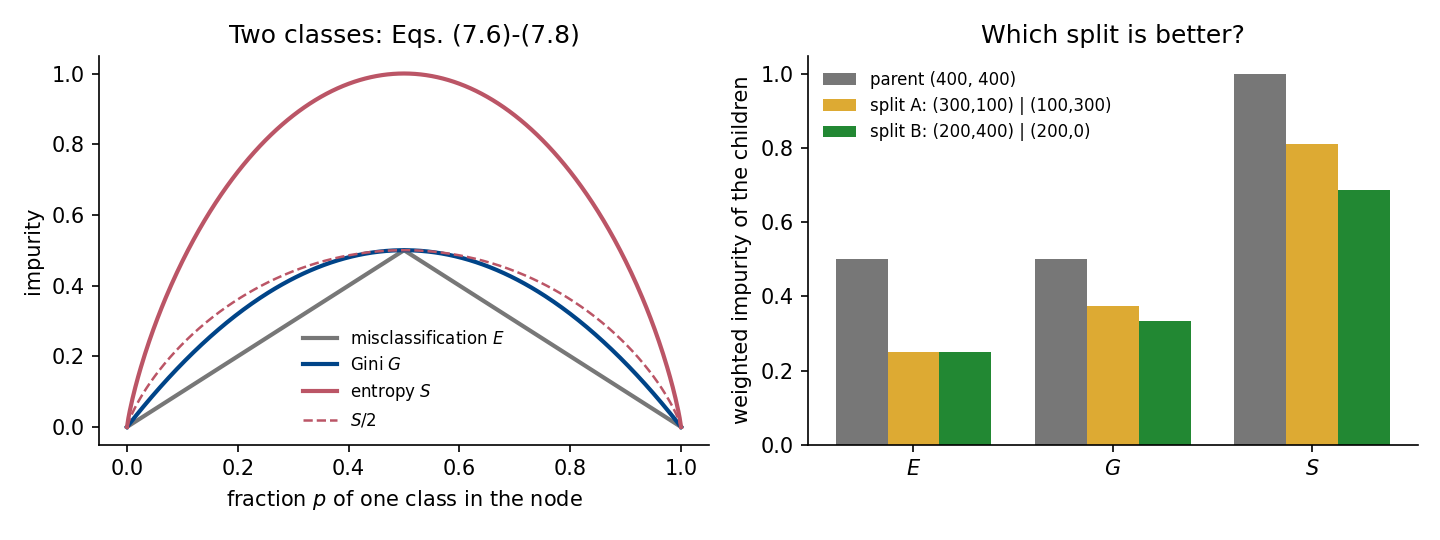

In [4]:
parent, A, B = fig_impurity("week46_impurity.png")
print("           E       G       S")
for name, v in [("parent ", parent), ("split A", A), ("split B", B)]:
    print(name, np.round(v, 4))
display(Image("week46_impurity.png"))

### 1.3 The CART split by hand: ten points in the plane

CART tries every feature and every midpoint between consecutive distinct
values, scores the split by the weighted impurity of the two children,
Eq. (7.9), and keeps the largest gain, Eq. (7.10). Ten points, two features,
two classes: twelve candidate thresholds at the root.

In [5]:
def toy_points():
    """Ten points in the plane, two classes, chosen so that CART needs three
    splits to separate them and so that the arithmetic can be done by hand."""
    X = np.array([[1.0, 1.0], [2.0, 2.0], [3.0, 2.0], [1.5, 4.0], [5.0, 1.0],      # class 0
                  [4.0, 4.0], [5.0, 3.0], [6.0, 5.0], [1.0, 5.0], [5.5, 4.5]])     # class 1
    y = np.array([0, 0, 0, 0, 0, 1, 1, 1, 1, 1])
    return X, y


def cart_scan(X, y, criterion="gini", classes=(0, 1)):
    """Score every candidate threshold of every feature: Eqs. (7.9)-(7.10).

    Returns a list of (feature, threshold, n_left, n_right, child_impurity, gain).
    """
    imp = gini if criterion == "gini" else entropy
    parent = imp(y, classes)
    rows = []
    for j in range(X.shape[1]):
        uniq = np.unique(X[:, j])
        for t in (uniq[:-1] + uniq[1:]) / 2.0:         # midpoints between sorted values
            mask = X[:, j] <= t
            nl, nr = mask.sum(), (~mask).sum()
            child = nl / len(y) * imp(y[mask], classes) + nr / len(y) * imp(y[~mask], classes)
            rows.append((j, t, nl, nr, child, parent - child))
    return parent, rows


def print_scan(X, y, criterion):
    parent, rows = cart_scan(X, y, criterion)
    print(f"\n{criterion}: parent impurity = {parent:.4f}")
    print(" feature  threshold  n_left n_right  C(k,t)   gain")
    for j, t, nl, nr, child, gain in rows:
        print(f"   x{j+1}      {t:5.2f}      {nl:2d}     {nr:2d}    {child:.4f}  {gain:.4f}")
    best = max(rows, key=lambda r: r[-1])
    print(f" best: x{best[0]+1} <= {best[1]:.2f}, gain {best[-1]:.4f}")
    return parent, rows, best


In [6]:
X, y = toy_points()
for crit in ["gini", "entropy"]:
    print_scan(X, y, crit)


gini: parent impurity = 0.5000
 feature  threshold  n_left n_right  C(k,t)   gain
   x1       1.25       2      8    0.5000  0.0000
   x1       1.75       3      7    0.4762  0.0238
   x1       2.50       4      6    0.4167  0.0833
   x1       3.50       5      5    0.3200  0.1800
   x1       4.50       6      4    0.4167  0.0833
   x1       5.25       8      2    0.3750  0.1250
   x1       5.75       9      1    0.4444  0.0556
   x2       1.50       2      8    0.3750  0.1250
   x2       2.50       4      6    0.1667  0.3333
   x2       3.50       5      5    0.3200  0.1800
   x2       4.25       7      3    0.2857  0.2143
   x2       4.75       8      2    0.3750  0.1250
 best: x2 <= 2.50, gain 0.3333

entropy: parent impurity = 1.0000
 feature  threshold  n_left n_right  C(k,t)   gain
   x1       1.25       2      8    1.0000  0.0000
   x1       1.75       3      7    0.9651  0.0349
   x1       2.50       4      6    0.8755  0.1245
   x1       3.50       5      5    0.7219  0.2781


Both criteria pick $x_2\le 2.5$: it makes a pure child of four points. A
split that isolates one point of each class ($x_1\le1.25$) gains nothing,
both children being as mixed as the parent; symmetric splits give symmetric
rows. The two criteria rank the twelve candidates identically here — the
usual, but not guaranteed, experience: the Gini gain is the variance between
the children, $\Delta_G=\sum_c w_c\|\mathbf p_c-\mathbf p\|^2$, the entropy
gain a Kullback–Leibler divergence, $\Delta_S=\sum_c w_c D_{\rm KL}(\mathbf
p_c\|\mathbf p)$; both are $\ge0$ and vanish exactly when every child has the
parent's proportions. The figure below plots the gain of
every candidate and the three splits the full tree ends up making (the tree
itself is grown by the `DecisionTree` class of Part 3, so the figure is
produced there).

## Part 2 — The ride data: a worked example with categorical features

Table 7.1: fourteen days, four categorical features (outlook, temperature,
humidity, wind), and whether we went for a ride. A categorical feature is
split the ID3 way, one child per value, and scored by the weighted impurity
of Eq. (7.9) over all children.

In [7]:
def ride_data():
    """Table 7.1: four categorical features and a binary target (ride = 1)."""
    rows = [
        ("Sunny", "Hot", "High", "Weak", 0), ("Sunny", "Hot", "High", "Strong", 1),
        ("Overcast", "Hot", "High", "Weak", 1), ("Rain", "Mild", "High", "Weak", 1),
        ("Rain", "Cool", "Normal", "Weak", 1), ("Rain", "Cool", "Normal", "Strong", 0),
        ("Overcast", "Cool", "Normal", "Strong", 1), ("Sunny", "Mild", "High", "Weak", 0),
        ("Sunny", "Cool", "Normal", "Weak", 1), ("Rain", "Mild", "Normal", "Weak", 1),
        ("Sunny", "Mild", "Normal", "Strong", 1), ("Overcast", "Mild", "High", "Strong", 1),
        ("Overcast", "Hot", "Normal", "Weak", 1), ("Rain", "Mild", "High", "Strong", 0)]
    features = ["Outlook", "Temperature", "Humidity", "Wind"]
    X = np.array([r[:4] for r in rows], dtype=object)
    y = np.array([r[4] for r in rows])
    return X, y, features


def categorical_split(X, y, j, criterion):
    """Weighted impurity after splitting on every value of categorical feature j:
    Eq. (7.9) with one child per value (the ID3 multiway split)."""
    imp = gini if criterion == "gini" else entropy
    total = 0.0
    for v in np.unique(X[:, j]):
        mask = X[:, j] == v
        total += mask.sum() / len(y) * imp(y[mask], [0, 1])
    return total


def ride_root_table():
    """Reproduces Eq. (7.13) and Table 7.2."""
    X, y, features = ride_data()
    G0, S0 = gini(y, [0, 1]), entropy(y, [0, 1])
    print(f"\nride data: root Gini = {G0:.4f}, root entropy = {S0:.4f}")
    print(f"{'feature':12s} {'Gini after':>11s} {'entropy after':>14s} {'info gain':>10s} {'Gini gain':>10s}")
    table = []
    for j, f in enumerate(features):
        g = categorical_split(X, y, j, "gini")
        s = categorical_split(X, y, j, "entropy")
        table.append((f, g, s, S0 - s, G0 - g))
        print(f"{f:12s} {g:11.4f} {s:14.4f} {S0 - s:10.4f} {G0 - g:10.4f}")
    return G0, S0, table


In [8]:
G0, S0, table = ride_root_table()


ride data: root Gini = 0.4082, root entropy = 0.8631
feature       Gini after  entropy after  info gain  Gini gain
Outlook           0.3429         0.6935     0.1696     0.0653
Temperature       0.4048         0.8571     0.0060     0.0034
Humidity          0.3673         0.7885     0.0747     0.0408
Wind              0.4048         0.8571     0.0060     0.0034


This is Eq. (7.13) and Table 7.2: at the root $G=0.4082$, $S=0.8631$ bits, and
both criteria choose **outlook**, because its *overcast* value is pure (all
four overcast days are rides). Humidity is second; temperature and wind are
nearly useless at the root.

### 2.1 Growing the whole tree (ID3)

Repeat the calculation in every impure branch: in the *rain* branch wind
separates the days perfectly (humidity and temperature both give
$C=7/15=0.467$); in the *sunny* branch humidity and wind tie (both
$C=0.267$ with the Gini index), our code takes the first in feature order,
and the *high humidity* child is then split by wind. The finished tree has
depth 3 and six leaves, all pure.

In [9]:
def build_id3(X, y, features, criterion="entropy", depth=0):
    """Grow a tree on categorical data: at every impure node choose the feature
    whose multiway split gives the smallest weighted impurity (largest gain),
    make one child per value, recurse.  Returns a nested dict."""
    imp = gini if criterion == "gini" else entropy
    node = {"n": len(y), "counts": (int(np.sum(y == 0)), int(np.sum(y == 1))),
            "impurity": imp(y, [0, 1]), "pred": int(np.round(np.mean(y)))}
    if node["impurity"] == 0 or not features:
        return node
    scores = [categorical_split(X, y, j, criterion) for j in range(len(features))]
    j = int(np.argmin(scores))                          # first feature wins a tie
    node["feature"], node["gain"] = features[j], node["impurity"] - scores[j]
    node["children"] = {}
    keep = [k for k in range(len(features)) if k != j]
    for v in np.unique(X[:, j]):
        mask = X[:, j] == v
        node["children"][v] = build_id3(X[mask][:, keep], y[mask], [features[k] for k in keep],
                                        criterion, depth + 1)
    return node


def print_tree(node, indent=""):
    if "feature" not in node:
        print(f"{indent}-> ride = {node['pred']}   (0: {node['counts'][0]}, 1: {node['counts'][1]})")
        return
    print(f"{indent}[{node['feature']}]  impurity {node['impurity']:.3f}, gain {node['gain']:.3f}")
    for v, child in node["children"].items():
        print(f"{indent}  {v}:")
        print_tree(child, indent + "    ")


In [10]:
trees = {}
X_r, y_r, features = ride_data()
for crit in ["gini", "entropy"]:
    trees[crit] = build_id3(X_r, y_r, features, crit)
    print(f"--- grown with the {crit}")
    print_tree(trees[crit])

--- grown with the gini
[Outlook]  impurity 0.408, gain 0.065
  Overcast:
    -> ride = 1   (0: 0, 1: 4)
  Rain:
    [Wind]  impurity 0.480, gain 0.480
      Strong:
        -> ride = 0   (0: 2, 1: 0)
      Weak:
        -> ride = 1   (0: 0, 1: 3)
  Sunny:
    [Humidity]  impurity 0.480, gain 0.213
      High:
        [Wind]  impurity 0.444, gain 0.444
          Strong:
            -> ride = 1   (0: 0, 1: 1)
          Weak:
            -> ride = 0   (0: 2, 1: 0)
      Normal:
        -> ride = 1   (0: 0, 1: 2)
--- grown with the entropy
[Outlook]  impurity 0.863, gain 0.170
  Overcast:
    -> ride = 1   (0: 0, 1: 4)
  Rain:
    [Wind]  impurity 0.971, gain 0.971
      Strong:
        -> ride = 0   (0: 2, 1: 0)
      Weak:
        -> ride = 1   (0: 0, 1: 3)
  Sunny:
    [Humidity]  impurity 0.971, gain 0.420
      High:
        [Wind]  impurity 0.918, gain 0.918
          Strong:
            -> ride = 1   (0: 0, 1: 1)
          Weak:
            -> ride = 0   (0: 2, 1: 0)
      Normal:


On these data the two criteria rank every split the same way at every node,
so with the same tie-breaking rule they grow the same tree; only the numbers
on the nodes differ. Drawn with matplotlib
(no graphviz needed):

In [11]:
def _n_leaves(node):
    return 1 if "children" not in node else sum(_n_leaves(k) for k in node["children"].values())


def _layout(node, x0, x1, depth, pos):
    """Assign (x, y) positions to the nodes of a nested-dict tree; each subtree
    gets a horizontal share proportional to its number of leaves."""
    pos[id(node)] = ((x0 + x1) / 2, -depth)
    if "children" in node:
        kids = list(node["children"].values())
        total = sum(_n_leaves(k) for k in kids)
        x = x0
        for kid in kids:
            w = (x1 - x0) * _n_leaves(kid) / total
            _layout(kid, x, x + w, depth + 1, pos)
            x += w


def draw_tree(node, ax, criterion):
    """Draw a nested-dict tree with matplotlib."""
    pos = {}
    _layout(node, 0, 1, 0, pos)
    sym = "G" if criterion == "gini" else "S"

    def rec(nd, parent_xy=None, edge=""):
        x, y = pos[id(nd)]
        if parent_xy is not None:
            ax.plot([parent_xy[0], x], [parent_xy[1] - 0.12, y + 0.12], color=GREY, lw=1.2, zorder=1)
            ax.text((parent_xy[0] + x) / 2, (parent_xy[1] + y) / 2, edge, fontsize=7.5,
                    ha="center", va="center", color=GREY,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
        n0, n1 = nd["counts"]
        if "feature" in nd:
            txt = f"{nd['feature']}?\n[{n0}, {n1}]  ${sym}$={nd['impurity']:.3f}"
            fc = "#e8eef7"
        else:
            txt = f"ride = {nd['pred']}\n[{n0}, {n1}]"
            fc = "#dcecdc" if nd["pred"] == 1 else "#f3dede"
        ax.text(x, y, txt, ha="center", va="center", fontsize=7.5, zorder=3,
                bbox=dict(boxstyle="round,pad=0.35", fc=fc, ec=GREY))
        for v, kid in nd.get("children", {}).items():
            rec(kid, (x, y), v)

    rec(node)
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-3.5, 0.4)
    ax.axis("off")


def fig_ride_trees(fname="week46_ride_trees.pdf"):
    X, y, features = ride_data()
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.6))
    trees = {}
    for a, crit in zip(ax, ["gini", "entropy"]):
        trees[crit] = build_id3(X, y, features, crit)
        draw_tree(trees[crit], a, crit)
        a.set_title(f"grown with the {crit}" + (" index" if crit == "gini" else ""), fontsize=10)
    fig.tight_layout()
    fig.savefig(fname)
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)
    return trees


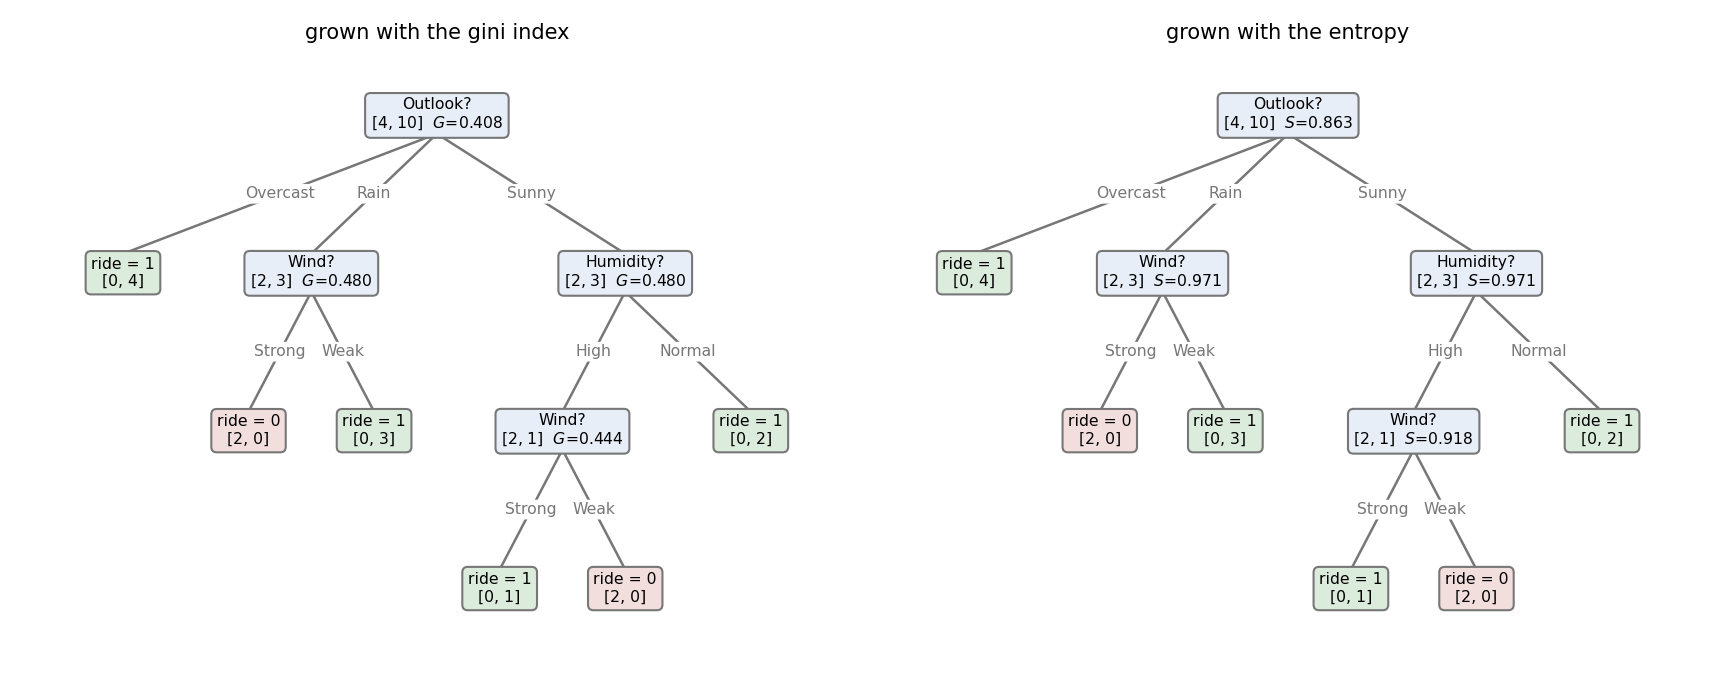

In [12]:
trees = fig_ride_trees("week46_ride_trees.png")
display(Image("week46_ride_trees.png"))

### 2.2 The same data in scikit-learn

scikit-learn's `DecisionTreeClassifier` is CART: every split is binary, and
since it needs numerical inputs the categorical features are one-hot encoded
first. The root asks `Outlook=Overcast <= 0.5`: the *true* (left) branch is
"not overcast", the false branch is our pure overcast leaf; the binary tree
needs more levels than the multiway ID3 tree to reach pure leaves (depth 5
and nine leaves with the seed 2026 — several splits tie, and another
`random_state` gives another, equally pure, tree).

In [13]:
def ride_sklearn(fname="week46_ride_sklearn.pdf"):
    """scikit-learn on the same data after one-hot encoding (CART splits are binary)."""
    from sklearn.preprocessing import OneHotEncoder
    from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
    X, y, features = ride_data()
    enc = OneHotEncoder(sparse_output=False)
    Xoh = enc.fit_transform(X)
    names = [n.replace("_", "=") for n in enc.get_feature_names_out(features)]
    clf = DecisionTreeClassifier(criterion="entropy", random_state=SEED).fit(Xoh, y)
    print("\nscikit-learn on the one-hot ride data (entropy):")
    print(export_text(clf, feature_names=names))
    print("depth", clf.get_depth(), "leaves", clf.get_n_leaves(), "train acc", clf.score(Xoh, y))
    fig, ax = plt.subplots(figsize=(10, 4.2))
    plot_tree(clf, feature_names=names, class_names=["no ride", "ride"], filled=True,
              rounded=True, impurity=True, fontsize=7, ax=ax)
    fig.tight_layout()
    fig.savefig(fname)
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)
    return clf


In [14]:
clf = ride_sklearn("week46_ride_sklearn.png")
display(Image("week46_ride_sklearn.png"))

TypeError: __init__() got an unexpected keyword argument 'sparse_output'

## Part 3 — A decision tree from scratch (Section 7.6)

The `DecisionTree` class below is CART for regression and classification.
`_best_split` is the double loop of the recipe: over the features (or a random
subset of them, when `max_features` is set — the random-forest hook of
Part 4) and over the midpoints between consecutive sorted values; the
weighted child impurity is Eq. (7.9), the gain Eq. (7.10), and the first
maximum wins a tie. The best gain starts at $-\infty$, not at $0$: an
admissible split with *zero* gain is accepted, because it may pay off one
level down — on XOR, $(0,0)\mapsto0$, $(0,1)\mapsto1$, $(1,0)\mapsto1$,
$(1,1)\mapsto0$, both root splits have zero gain, yet one level further all
four leaves are pure (a rule "stop when the gain is zero" returns a single
leaf at 50% accuracy; scikit-learn's `min_impurity_decrease` defaults to 0
for the same reason). A node becomes a leaf only when no admissible split
exists or a stopping rule fires. When `max_features` is set, the features
are visited in a fresh random order and the search stops after the first
$m$ of them as soon as one has produced an admissible split (if none has,
more are inspected, as scikit-learn does). `_build` applies the stopping
rules and recurses; `predict` walks each point from the root to a leaf.

In [15]:
class Node:
    __slots__ = ("feature", "threshold", "left", "right", "value", "n")

    def __init__(self, value=None, n=0):
        self.feature = self.threshold = self.left = self.right = None
        self.value, self.n = value, n


class DecisionTree:
    """CART for regression and classification.

    task       : "classification" or "regression"
    criterion  : "gini" or "entropy" (classification only)
    max_features: if set, only m random features are tried at each split
                  (more only if none of them can split the node) -- this is
                  what turns bagging into a random forest.
    Zero-gain splits are allowed (XOR needs one); a node becomes a leaf only
    when no admissible split exists or a stopping rule fires.
    """

    def __init__(self, task="classification", criterion="gini", max_depth=None,
                 min_samples_split=2, min_samples_leaf=1, max_features=None,
                 rng=None):
        self.task, self.criterion = task, criterion
        self.max_depth = np.inf if max_depth is None else max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.rng = np.random.default_rng() if rng is None else rng

    def _impurity(self, y):
        if self.task == "regression":
            return mse_impurity(y)
        return (gini(y, self.classes_) if self.criterion == "gini"
                else entropy(y, self.classes_))

    def _leaf_value(self, y):
        if self.task == "regression":
            return y.mean()                              # the optimal constant
        counts = [np.sum(y == c) for c in self.classes_]
        return self.classes_[int(np.argmax(counts))]     # majority vote

    def _best_split(self, X, y):
        n, p = X.shape
        features = np.arange(p)
        if self.max_features is not None and self.max_features < p:
            features = self.rng.permutation(p)           # random forest: a fresh random order
        parent = self._impurity(y)
        best_gain, best_j, best_t = -np.inf, None, None  # any admissible split beats "none"
        for rank, j in enumerate(features):
            if (self.max_features is not None and rank >= self.max_features
                    and best_j is not None):
                break                                    # m features tried, one of them works
            xs = X[:, j]
            uniq = np.unique(xs)
            if len(uniq) < 2:
                continue
            for t in (uniq[:-1] + uniq[1:]) / 2.0:       # candidate midpoints
                mask = xs <= t
                nl, nr = mask.sum(), n - mask.sum()
                if nl < self.min_samples_leaf or nr < self.min_samples_leaf:
                    continue
                child = (nl / n) * self._impurity(y[mask]) + (nr / n) * self._impurity(y[~mask])
                gain = parent - child                    # Eq. (7.10)
                if gain > best_gain + 1e-12:
                    best_gain, best_j, best_t = gain, j, t
        return best_gain, best_j, best_t

    def _build(self, X, y, depth):
        node = Node(self._leaf_value(y), len(y))
        if (depth >= self.max_depth or len(y) < self.min_samples_split
                or len(np.unique(y)) == 1):
            return node
        gain, j, t = self._best_split(X, y)
        if j is None:                                    # no admissible split (gain 0 is fine)
            return node
        mask = X[:, j] <= t
        node.feature, node.threshold = j, t
        node.left = self._build(X[mask], y[mask], depth + 1)
        node.right = self._build(X[~mask], y[~mask], depth + 1)
        return node

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y)
        if self.task == "classification":
            self.classes_ = np.unique(y)
        self.root_ = self._build(X, y, 0)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        out = []
        for x in X:
            node = self.root_
            while node.feature is not None:              # walk to a leaf
                node = node.left if x[node.feature] <= node.threshold else node.right
            out.append(node.value)
        return np.array(out)

    def depth(self):
        def d(node):
            return 0 if node.feature is None else 1 + max(d(node.left), d(node.right))
        return d(self.root_)

    def n_leaves(self):
        def c(node):
            return 1 if node.feature is None else c(node.left) + c(node.right)
        return c(self.root_)


### 3.0 XOR: the zero-gain root

In [16]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], float)
y_xor = np.array([0, 1, 1, 0])
for crit in ["gini", "entropy"]:
    t = DecisionTree("classification", crit).fit(X_xor, y_xor)
    print(f"XOR, {crit:8s}: depth {t.depth()}, leaves {t.n_leaves()}, "
          f"training accuracy {np.mean(t.predict(X_xor) == y_xor):.2f}")

XOR, gini    : depth 2, leaves 4, training accuracy 1.00
XOR, entropy : depth 2, leaves 4, training accuracy 1.00


### 3.1 The ten points again, and the tree CART grows

In [17]:
def draw_splits(node, ax, xlim, ylim, counter=None):
    """Draw the axis-aligned splits of a fitted tree, each inside the box of
    its node, numbered in the order in which CART makes them (depth first)."""
    if node.feature is None:
        return
    counter = [0] if counter is None else counter
    counter[0] += 1
    col = [GREEN, YELLOW, GREY, BLUE][min(counter[0] - 1, 3)]
    lab = f"split {counter[0]}: $x_{node.feature + 1}\\leq{node.threshold:g}$"
    if node.feature == 0:
        ax.plot([node.threshold] * 2, ylim, color=col, lw=2, zorder=2, label=lab)
        draw_splits(node.left, ax, (xlim[0], node.threshold), ylim, counter)
        draw_splits(node.right, ax, (node.threshold, xlim[1]), ylim, counter)
    else:
        ax.plot(xlim, [node.threshold] * 2, color=col, lw=2, zorder=2, label=lab)
        draw_splits(node.left, ax, xlim, (ylim[0], node.threshold), counter)
        draw_splits(node.right, ax, xlim, (node.threshold, ylim[1]), counter)


def fig_cart_scan(fname="week46_cart_scan.pdf"):
    X, y = toy_points()
    fig, ax = plt.subplots(1, 3, figsize=(11.5, 3.6))

    # the points and the first split
    for c, m, col in [(0, "o", BLUE), (1, "s", RED)]:
        ax[0].scatter(X[y == c, 0], X[y == c, 1], marker=m, s=70, color=col,
                      edgecolor="k", label=f"class {c}", zorder=3)
    for i, (x1, x2) in enumerate(X):
        ax[0].annotate(str(i + 1), (x1, x2), textcoords="offset points", xytext=(6, 4), fontsize=8)
    tree = DecisionTree("classification", "gini").fit(X, y)
    draw_splits(tree.root_, ax[0], (0.5, 6.5), (0.5, 5.6))
    ax[0].set_xlim(0.5, 6.5)
    ax[0].set_ylim(0.5, 6.6)
    ax[0].set_xlabel("$x_1$")
    ax[0].set_ylabel("$x_2$")
    ax[0].set_title("Ten points and the three CART splits")
    ax[0].legend(frameon=False, fontsize=7.5, loc="upper center", ncol=3, columnspacing=0.8)

    # gain against threshold for both features, both criteria
    for k, (crit, col) in enumerate([("gini", BLUE), ("entropy", RED)]):
        parent, rows = cart_scan(X, y, crit)
        for j, ls in [(0, "-"), (1, "--")]:
            r = [row for row in rows if row[0] == j]
            ts = [row[1] for row in r]
            gs = [row[-1] for row in r]
            ax[1 + k].plot(ts, gs, ls, marker="o", color=col, label=f"$x_{j+1}\\leq t$")
        best = max(rows, key=lambda r: r[-1])
        ax[1 + k].scatter([best[1]], [best[-1]], s=160, facecolor="none", edgecolor=GREEN, lw=2, zorder=4)
        ax[1 + k].set_xlabel("threshold $t$")
        ax[1 + k].set_ylabel("gain $\\Delta$, Eq. (7.10)")
        ax[1 + k].set_title(f"{crit}: parent = {parent:.3f}, best $x_{best[0]+1}\\leq{best[1]:.1f}$")
        ax[1 + k].legend(frameon=False, fontsize=8)
    fig.tight_layout()
    fig.savefig(fname)
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)


depth 3  leaves 4  training accuracy 1.0


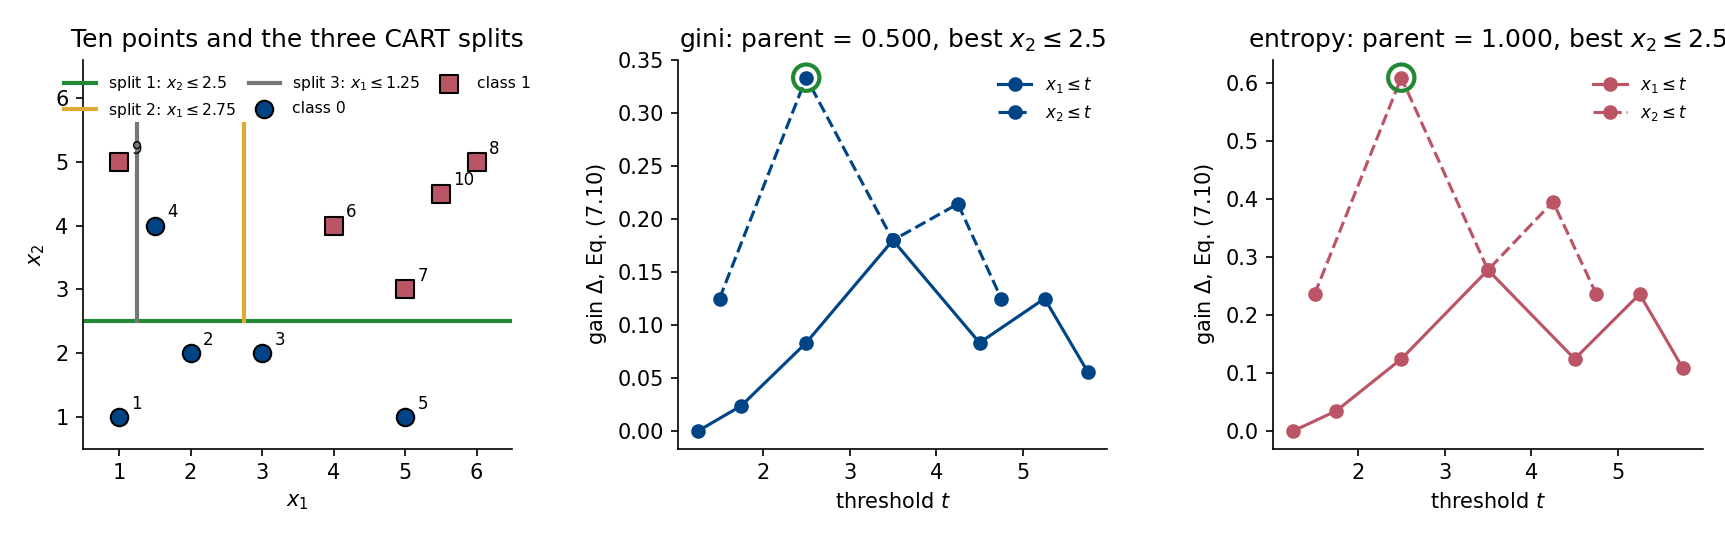

In [18]:
tree = DecisionTree("classification", "gini").fit(X, y)
print("depth", tree.depth(), " leaves", tree.n_leaves(), " training accuracy", np.mean(tree.predict(X) == y))
fig_cart_scan("week46_cart_scan.png")
display(Image("week46_cart_scan.png"))

Split 1 is $x_2\le2.5$ (gain 0.333); split 2, inside the six points above it,
is $x_1\le2.75$ (gain 0.111); split 3 separates the last two points
($x_1\le1.25$ — a tie with $x_2\le4.5$, broken by feature order). Depth 3,
four leaves, training error zero.

### 3.2 Checking against scikit-learn on the moons

Same accuracies and the same number of leaves at every depth; at unlimited
depth the test accuracies differ slightly because ties between equally good
splits are broken differently. The fully grown tree fits the training data
perfectly and generalises no better than depth 3 — the signature of the
variance term of the bias–variance decomposition growing with the depth.

In [19]:
def moons_check(n=400, noise=0.3, depths=(1, 3, 5, None)):
    """Our tree against scikit-learn's on the moons data (the table of Section 7.6)."""
    from sklearn.datasets import make_moons
    from sklearn.model_selection import train_test_split
    from sklearn.tree import DecisionTreeClassifier
    X, y = make_moons(n_samples=n, noise=noise, random_state=SEED)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=SEED)
    print("\nmoons, n = %d, noise = %.2f: our CART against scikit-learn" % (n, noise))
    rows = []
    for d in depths:
        t0 = time.time()
        ours = DecisionTree("classification", "gini", max_depth=d).fit(Xtr, ytr)
        dt = time.time() - t0
        sk = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(Xtr, ytr)
        row = (d, np.mean(ours.predict(Xtr) == ytr), np.mean(ours.predict(Xte) == yte),
               sk.score(Xtr, ytr), sk.score(Xte, yte), ours.n_leaves(), sk.get_n_leaves(), dt)
        rows.append(row)
        print(f"depth={str(d):4s} ours train={row[1]:.4f} test={row[2]:.4f} | "
              f"sklearn train={row[3]:.4f} test={row[4]:.4f} | leaves {row[5]} / {row[6]} | {dt:.2f} s")
    return rows


In [20]:
rows = moons_check()


moons, n = 400, noise = 0.30: our CART against scikit-learn
depth=1    ours train=0.8267 test=0.7800 | sklearn train=0.8267 test=0.7800 | leaves 2 / 2 | 0.03 s
depth=3    ours train=0.9000 test=0.8600 | sklearn train=0.9000 test=0.8600 | leaves 7 / 7 | 0.05 s
depth=5    ours train=0.9633 test=0.8600 | sklearn train=0.9633 test=0.8600 | leaves 18 / 18 | 0.06 s
depth=None ours train=1.0000 test=0.8600 | sklearn train=1.0000 test=0.8400 | leaves 33 / 33 | 0.07 s


### 3.3 Regression trees are staircases

The Runge function $1/(1+25x^2)$ with noise $\sigma=0.1$. A depth-$d$ tree has
at most $2^d$ leaves, each predicting a constant. The training MSE falls to
zero, the test MSE is smallest at depth 4 and rises again — and never reaches
the noise floor $0.01$, because a staircase is a poor model for one smooth
feature. (In practice the depth is chosen on validation data, not by reading
off the minimum of the test curve.)

In [21]:
def runge_data(n=200, noise=0.1, seed=SEED):
    """The Runge function 1/(1+25x^2) on [-1, 1] with Gaussian noise."""
    rng = np.random.default_rng(seed)
    x = np.sort(rng.uniform(-1, 1, n))
    y = 1.0 / (1.0 + 25.0 * x**2) + noise * rng.standard_normal(n)
    return x[:, None], y


def fig_regression_tree(fname="week46_regression_tree.pdf"):
    from sklearn.tree import DecisionTreeRegressor
    X, y = runge_data(200)
    Xte, yte = runge_data(200, seed=SEED + 1)
    xg = np.linspace(-1, 1, 600)[:, None]
    fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
    ax[0].scatter(X, y, s=10, color=GREY, alpha=0.6, label="training data")
    ax[0].plot(xg, 1 / (1 + 25 * xg**2), color="k", lw=1, ls=":", label="Runge function")
    results = []
    for d, col in zip([1, 2, 4, 8], [YELLOW, GREEN, BLUE, RED]):
        tree = DecisionTree("regression", max_depth=d).fit(X, y)
        ax[0].plot(xg, tree.predict(xg), color=col, lw=1.6, label=f"depth {d} ({tree.n_leaves()} leaves)")
    ax[0].set_xlabel("$x$")
    ax[0].set_ylabel("$y$")
    ax[0].set_title("Regression trees are staircases")
    ax[0].legend(frameon=False, fontsize=7.5)

    depths = list(range(1, 13))
    tr, te, sk_te = [], [], []
    for d in depths:
        tree = DecisionTree("regression", max_depth=d).fit(X, y)
        tr.append(np.mean((tree.predict(X) - y)**2))
        te.append(np.mean((tree.predict(Xte) - yte)**2))
        sk = DecisionTreeRegressor(max_depth=d, random_state=SEED).fit(X, y)
        sk_te.append(np.mean((sk.predict(Xte) - yte)**2))
        results.append((d, tr[-1], te[-1], sk_te[-1]))
    ax[1].plot(depths, tr, "o-", color=BLUE, label="train MSE (ours)")
    ax[1].plot(depths, te, "s-", color=RED, label="test MSE (ours)")
    ax[1].plot(depths, sk_te, "x--", color=GREY, label="test MSE (scikit-learn)")
    ax[1].axhline(0.01, color="k", lw=0.8, ls=":", label="noise variance $\\sigma^2=0.01$")
    ax[1].set_xlabel("maximum depth")
    ax[1].set_ylabel("MSE")
    ax[1].set_title("Deeper is not better: the variance takes over")
    ax[1].legend(frameon=False, fontsize=7.5)
    fig.tight_layout()
    fig.savefig(fname)
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)
    print("\nRunge regression tree: depth, train MSE, test MSE (ours), test MSE (sklearn)")
    for r in results:
        print("  %2d  %.4f  %.4f  %.4f" % r)
    return results



Runge regression tree: depth, train MSE, test MSE (ours), test MSE (sklearn)
   1  0.0758  0.0683  0.0683
   2  0.0354  0.0336  0.0336
   3  0.0118  0.0200  0.0200
   4  0.0084  0.0181  0.0181
   5  0.0054  0.0192  0.0192
   6  0.0037  0.0193  0.0193
   7  0.0022  0.0201  0.0201
   8  0.0012  0.0205  0.0205
   9  0.0005  0.0211  0.0211
  10  0.0001  0.0213  0.0213
  11  0.0000  0.0214  0.0214
  12  0.0000  0.0215  0.0215


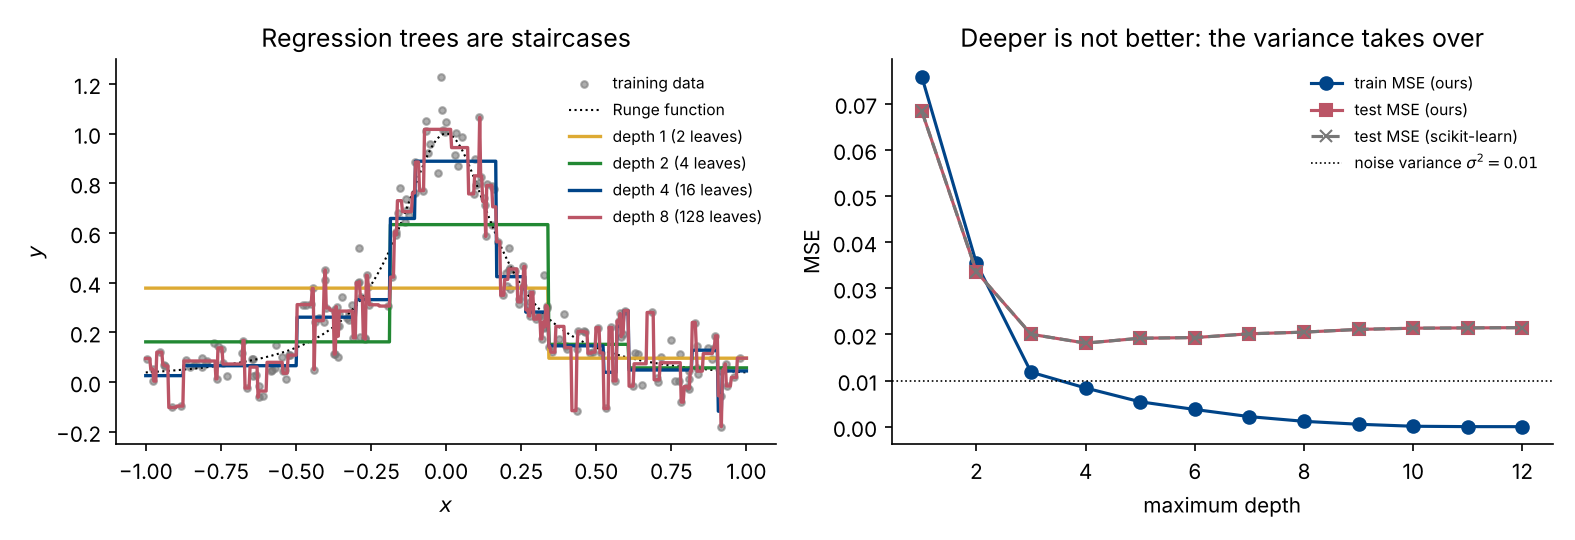

In [22]:
results = fig_regression_tree("week46_regression_tree.png")
display(Image("week46_regression_tree.png"))

### 3.4 Recursive binary splitting in pictures

Two features and a response with two steps, $y = 3 + 4[x_1>0.5] + 3[x_2>0.5]$
plus noise: the whole data set in one box with its mean and the candidate
cutpoints (the midpoints between consecutive values of each feature), the
first split, the second level with four boxes, and the same four boxes drawn
as a tree. The number under each title is Eq. (7.1).

In [22]:
def regression_boxes_data(n=36, noise=0.5, seed=SEED):
    """Two features on the unit square and a response with two steps,
    y = 3 + 4 [x1 > 0.5] + 3 [x2 > 0.5] + noise: four plateaus that CART
    should recover with two levels of splits (greedy: x1 first, since its
    step is larger)."""
    rng = np.random.default_rng(seed)
    X = rng.uniform(0.04, 0.96, (n, 2))
    f = 3.0 + 4.0 * (X[:, 0] > 0.5) + 3.0 * (X[:, 1] > 0.5)
    y = f + noise * rng.standard_normal(n)
    return X, y


def leaf_boxes(node, xlim, ylim, boxes=None):
    """Walk a fitted regression tree and return (xlim, ylim, mean, n) for every leaf."""
    boxes = [] if boxes is None else boxes
    if node.feature is None:
        boxes.append((xlim, ylim, node.value, node.n))
        return boxes
    if node.feature == 0:
        leaf_boxes(node.left, (xlim[0], node.threshold), ylim, boxes)
        leaf_boxes(node.right, (node.threshold, xlim[1]), ylim, boxes)
    else:
        leaf_boxes(node.left, xlim, (ylim[0], node.threshold), boxes)
        leaf_boxes(node.right, xlim, (node.threshold, ylim[1]), boxes)
    return boxes


def draw_cart_tree(node, ax, feature_names=("x_1", "x_2"), fmt="{:.2f}"):
    """Draw a fitted DecisionTree (regression) as a diagram: tests in the
    internal nodes, the leaf means in the leaves, labelled R_1, R_2, ..."""
    def n_leaves(nd):
        return 1 if nd.feature is None else n_leaves(nd.left) + n_leaves(nd.right)

    def depth(nd):
        return 0 if nd.feature is None else 1 + max(depth(nd.left), depth(nd.right))

    counter = [0]

    def rec(nd, x0, x1, d, parent=None, edge=""):
        x, y = (x0 + x1) / 2, -d
        if parent is not None:
            ax.plot([parent[0], x], [parent[1] - 0.15, y + 0.15], color=GREY, lw=1.2, zorder=1)
            ax.text((parent[0] + x) / 2, (parent[1] + y) / 2, edge, fontsize=10.5, ha="center",
                    va="center", color=GREY, bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none"))
        if nd.feature is None:
            counter[0] += 1
            txt = f"$R_{counter[0]}$\n$\\bar y=$" + fmt.format(nd.value) + f"\n$n={nd.n}$"
            ax.text(x, y, txt, ha="center", va="center", fontsize=11.25, zorder=3,
                    bbox=dict(boxstyle="round,pad=0.3", fc="#dcecdc", ec=GREY))
            return
        txt = f"${feature_names[nd.feature]}\\leq{nd.threshold:.2f}$?"
        ax.text(x, y, txt, ha="center", va="center", fontsize=12, zorder=3,
                bbox=dict(boxstyle="round,pad=0.3", fc="#e8eef7", ec=GREY))
        nl, nr = n_leaves(nd.left), n_leaves(nd.right)
        xm = x0 + (x1 - x0) * nl / (nl + nr)
        rec(nd.left, x0, xm, d + 1, (x, y), "yes")
        rec(nd.right, xm, x1, d + 1, (x, y), "no")

    rec(node, 0, 1, 0)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-depth(node) - 0.5, 0.5)
    ax.axis("off")


def fig_regression_boxes(fname="week46_boxes.pdf"):
    """Four panels: the whole data set in one box with its mean and the candidate
    cutpoints; after the first split; after the second level of splits; and the
    tree that encodes the boxes.  Points are coloured by y, boxes by their mean."""
    X, y = regression_boxes_data()
    xlim, ylim = (0.0, 1.0), (0.0, 1.0)
    cmap = plt.get_cmap("viridis")
    norm = plt.Normalize(y.min() - 0.5, y.max() + 0.5)
    plt.rcParams.update({"font.size": 15, "axes.titlesize": 13, "axes.labelsize": 15,
                         "xtick.labelsize": 12, "ytick.labelsize": 12})
    fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.6))
    axes = axes.ravel()
    rng = np.random.default_rng(SEED)
    for k, (ax, d) in enumerate(zip(axes[:3], [0, 1, 2])):
        tree = DecisionTree("regression", max_depth=d, min_samples_leaf=3).fit(X, y)
        boxes = leaf_boxes(tree.root_, xlim, ylim)
        for j, ((a, b), (c, e), m, n) in enumerate(boxes):
            ax.add_patch(plt.Rectangle((a, c), b - a, e - c, facecolor=cmap(norm(m)), alpha=0.35,
                                       edgecolor="k", lw=1.2))
            ax.text(a + 0.02, e - 0.03, f"$R_{j+1}$", ha="left", va="top", fontsize=13.5, fontweight="bold")
            ax.text((a + b) / 2, c + 0.04, f"$\\bar y_{{R_{j+1}}}={m:.2f}$, $n={n}$", ha="center",
                    va="bottom", fontsize=11.25, bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
        ax.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap, norm=norm, s=60, edgecolor="k", lw=0.5, zorder=3)
        # a few labelled points
        if k == 0:
            picks = rng.choice(len(y), 6, replace=False)
        for i in picks:
            ax.annotate(f"$y={y[i]:.1f}$", (X[i, 0], X[i, 1]), textcoords="offset points",
                        xytext=(-5, 3) if X[i, 0] > 0.8 else (5, 3), ha="right" if X[i, 0] > 0.8 else "left", fontsize=9.75)
        if d == 0:                                      # candidate cutpoints: the midpoints
            for jj, side in [(0, "bottom"), (1, "left")]:
                u = np.unique(X[:, jj])
                mids = (u[:-1] + u[1:]) / 2
                if jj == 0:
                    ax.plot(mids, np.full_like(mids, 0.012), "|", color=RED, ms=9, mew=1.3)
                else:
                    ax.plot(np.full_like(mids, 0.012), mids, "_", color=RED, ms=9, mew=1.3)
        # label the cut lines
        def label_cuts(nd, xl, yl, depth_=0):
            if nd.feature is None:
                return
            if nd.feature == 0:
                ax.text(nd.threshold + 0.01, yl[0] + 0.12, f"$x_1\\leq s={nd.threshold:.2f}$",
                        rotation=90, fontsize=10.5, color=RED, ha="left", va="bottom")
                label_cuts(nd.left, (xl[0], nd.threshold), yl, depth_ + 1)
                label_cuts(nd.right, (nd.threshold, xl[1]), yl, depth_ + 1)
            else:
                ax.text(xl[1] - 0.01, nd.threshold - 0.012, f"$x_2\\leq s={nd.threshold:.2f}$",
                        fontsize=10.5, color=RED, ha="right", va="top")
                label_cuts(nd.left, xl, (yl[0], nd.threshold), depth_ + 1)
                label_cuts(nd.right, xl, (nd.threshold, yl[1]), depth_ + 1)
        label_cuts(tree.root_, xlim, ylim)
        ax.set_xlim(*xlim)
        ax.set_ylim(*ylim)
        ax.set_xlabel("$x_1$")
        ax.set_ylabel("$x_2$")
        rss = float(np.sum((tree.predict(X) - y) ** 2))
        ax.set_title(["(a) one box, and the candidate cutpoints (red ticks)", "(b) the first split",
                      "(c) the second level: four boxes"][k] + f"\nEq. (7.1) = {rss:.1f}", fontsize=12.75)
    tree = DecisionTree("regression", max_depth=2, min_samples_leaf=3).fit(X, y)
    draw_cart_tree(tree.root_, axes[3])
    axes[3].set_title("(d) the same four boxes as a tree", fontsize=13.5)
    fig.subplots_adjust(hspace=0.32, wspace=0.25)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    cb = fig.colorbar(sm, ax=axes[:3].tolist(), fraction=0.025, pad=0.02, location="right")
    cb.set_label("$y$ (points) and $\\bar y_{R_j}$ (boxes)")
    fig.savefig(fname, bbox_inches="tight")
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150, bbox_inches="tight")
    plt.close(fig)
    plt.rcParams.update({"font.size": 10, "axes.titlesize": "large", "axes.labelsize": "medium",
                         "xtick.labelsize": "medium", "ytick.labelsize": "medium"})
    print("\nregression boxes: y range %.2f..%.2f" % (y.min(), y.max()))
    for d in (0, 1, 2):
        t = DecisionTree("regression", max_depth=d, min_samples_leaf=3).fit(X, y)
        print("  depth %d: RSS %.2f, leaves %d" % (d, np.sum((t.predict(X) - y) ** 2), t.n_leaves()))
        for (a, b), (c, e), m, n in leaf_boxes(t.root_, xlim, ylim):
            print("     box x1 in (%.2f,%.2f], x2 in (%.2f,%.2f]: mean %.2f, n=%d" % (a, b, c, e, m, n))
    return X, y



regression boxes: y range 2.02..11.13
  depth 0: RSS 214.24, leaves 1
     box x1 in (0.00,1.00], x2 in (0.00,1.00]: mean 6.20, n=36
  depth 1: RSS 97.02, leaves 2
     box x1 in (0.00,0.51], x2 in (0.00,1.00]: mean 4.29, n=17
     box x1 in (0.51,1.00], x2 in (0.00,1.00]: mean 7.90, n=19
  depth 2: RSS 9.28, leaves 4
     box x1 in (0.00,0.51], x2 in (0.00,0.54]: mean 2.70, n=9
     box x1 in (0.00,0.51], x2 in (0.54,1.00]: mean 6.08, n=8
     box x1 in (0.51,1.00], x2 in (0.00,0.49]: mean 6.93, n=13
     box x1 in (0.51,1.00], x2 in (0.49,1.00]: mean 10.02, n=6


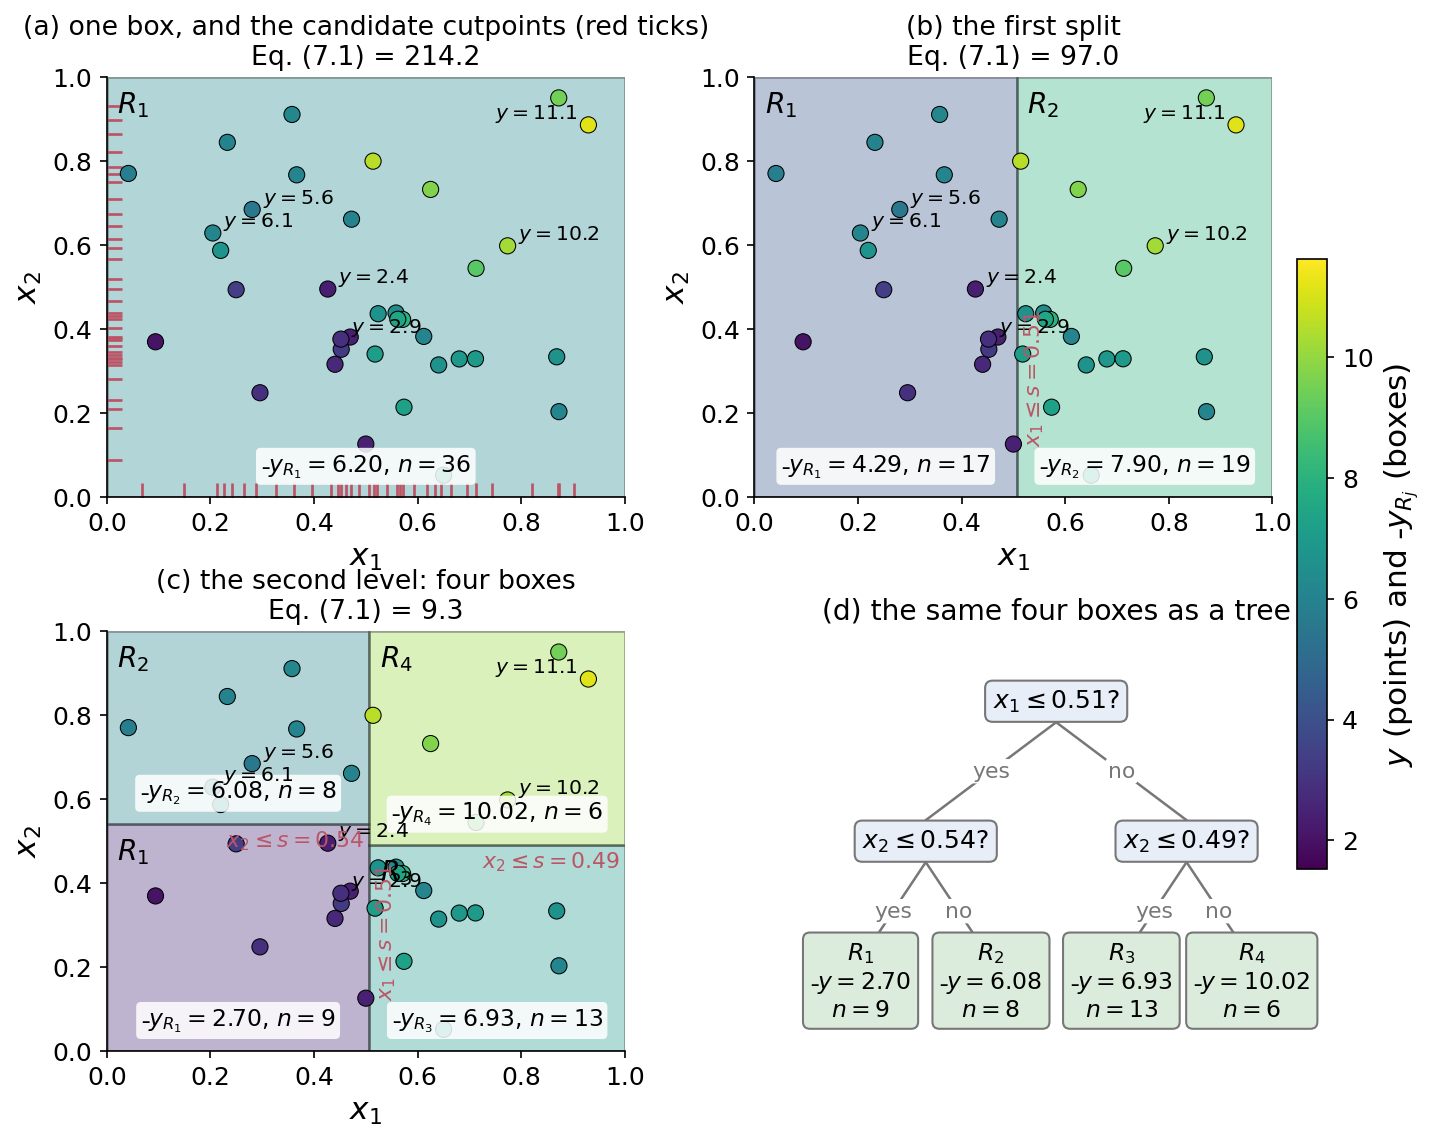

In [23]:
Xb, yb = fig_regression_boxes("week46_boxes.png")
display(Image("week46_boxes.png"))

## Part 4 — Many trees

### 4.1 Why averaging helps, and the catch: Eq. (7.16)

At a fixed input $x$, average $B$ predictors that are random through their
training data, each with the same mean, the same variance $\sigma_T^2$ (the
variance of *one tree*, not the noise variance $\sigma^2$) and pairwise
correlation $\rho$:

$$\mathrm{var}(\bar f)=\rho\sigma_T^2+\frac{1-\rho}{B}\sigma_T^2 .$$

The mean, and hence the bias, is untouched; the second term vanishes as
$B\to\infty$; the first does not depend on $B$ at all. Writing a bagged tree
as $h(x;D,\Theta_b)$ with $D$ the training set and $\Theta_b$ the bootstrap
draw, the law of total variance gives the floor its meaning:
$\mathrm{var}(\bar f)=\mathrm{var}_D\,\mu_D(x)+\mathbb E_D v_D(x)/B$ with
$\mu_D=\mathbb E_\Theta[h\mid D]$ the infinite-ensemble prediction and
$v_D=\mathrm{var}_\Theta(h\mid D)$ — the trees are independent given $D$ and
correlated only through the data set they share, and
$\rho\sigma_T^2=\mathrm{var}_D\mu_D$.

We measure all three quantities exactly in this sense, on bagged deep
regression trees: 200 independent training sets of the noisy Runge function,
100 trees on bootstrap samples of each, evaluated at the same grid of test
points. Across the replicates, at each test point, $\sigma_T^2$ is the
variance of one tree's prediction, $\rho$ the mean correlation between two
trees of the same ensemble (from
$\mathrm{var}(\sum_b f_b)=B\sigma_T^2+B(B-1)\rho\sigma_T^2$), and the
variance of the average of the first $B$ trees is compared with the formula
— no fitting; the panel shows the averages over the test points.
The third panel is Condorcet's jury theorem: $B$ independent voters, each right
with probability $p>1/2$.

In [24]:
def variance_of_average(B, rho, sigma2=1.0):
    """Eq. (7.16): var(fbar) = rho sigma^2 + (1 - rho) sigma^2 / B."""
    return rho * sigma2 + (1 - rho) * sigma2 / B


def measured_bagging_variance(n_train=200, n_rep=200, Bs=(1, 2, 5, 10, 20, 50, 100), seed=SEED):
    """Measure the three quantities of Eq. (7.16) on bagged deep regression trees.

    We draw n_rep independent training sets (fresh noise on the Runge function),
    fit Bmax deep trees to bootstrap samples of each, and evaluate them at a
    grid of test points.  Over the n_rep replicates, at each x:
      sigma^2 = variance of one tree's prediction,
      rho     = mean correlation between two different trees of the same ensemble
                (from var(sum_b f_b) = B sigma^2 + B(B-1) rho sigma^2),
      and the variance of the average of the first B trees, for each B in Bs.
    Averaged over x.  Uses scikit-learn's tree for speed."""
    from sklearn.tree import DecisionTreeRegressor
    rng = np.random.default_rng(seed)
    xg = np.linspace(-0.95, 0.95, 40)[:, None]
    Bmax = max(Bs)
    preds = np.empty((n_rep, Bmax, len(xg)))
    for r in range(n_rep):
        X, y = runge_data(n_train, seed=seed + 1000 + r)
        for b in range(Bmax):
            idx = rng.integers(0, n_train, n_train)
            tree = DecisionTreeRegressor(random_state=int(rng.integers(1 << 30)))
            preds[r, b] = tree.fit(X[idx], y[idx]).predict(xg)
    var_one = preds.var(axis=0)                              # (Bmax, nx): over replicates
    sigma2 = var_one.mean()
    var_sum = preds.sum(axis=1).var(axis=0)                  # (nx,)
    mean_cov = (var_sum - var_one.sum(axis=0)) / (Bmax * (Bmax - 1))
    rho = (mean_cov / var_one.mean(axis=0)).mean()
    measured = [preds[:, :B].mean(axis=1).var(axis=0).mean() for B in Bs]
    return sigma2, rho, Bs, measured


def condorcet(p, B):
    """Probability that a majority of B independent voters, each right with
    probability p, is right (B odd): the binomial tail of Eq. (2.binomial)."""
    from scipy.stats import binom
    return float(binom.sf(B // 2, B, p))                    # P(X >= B//2 + 1)


def fig_variance(fname="week46_variance.pdf"):
    sigma2, rho, Bs, measured = measured_bagging_variance()
    print(f"\nbagged regression trees: sigma^2 (one tree) = {sigma2:.4f}, mean pairwise rho = {rho:.3f}")
    Bg = np.arange(1, 101)
    fig, ax = plt.subplots(1, 3, figsize=(11.5, 3.5))
    for r, col in zip([0.0, 0.2, 0.5, 0.8], [GREEN, BLUE, YELLOW, RED]):
        ax[0].plot(Bg, variance_of_average(Bg, r), color=col, lw=1.8, label=f"$\\rho={r}$")
        if r > 0:
            ax[0].axhline(r, color=col, lw=0.8, ls=":")
    ax[0].set_xscale("log")
    ax[0].set_xlabel("number of predictors $B$")
    ax[0].set_ylabel("var$(\\bar f)/\\sigma_T^2$")
    ax[0].set_title("Eq. (7.16): the floor $\\rho\\sigma_T^2$")
    ax[0].legend(frameon=False, fontsize=8)

    ax[1].plot(Bs, measured, "o", color=RED, ms=7, label="measured, bagged deep trees")
    ax[1].plot(Bg, variance_of_average(Bg, rho, sigma2), color=BLUE, lw=1.8,
               label=f"Eq. (7.16) with measured $\\rho={rho:.2f}$")
    ax[1].plot(Bg, sigma2 / Bg, color=GREY, lw=1.2, ls="--", label="$\\sigma_T^2/B$ (independent)")
    ax[1].axhline(rho * sigma2, color=RED, lw=0.8, ls=":")
    ax[1].set_xscale("log")
    ax[1].set_yscale("log")
    ax[1].set_xlabel("number of trees $B$")
    ax[1].set_ylabel("variance of the bagged prediction")
    ax[1].set_title("Runge data: formula against measurement")
    ax[1].legend(frameon=False, fontsize=7.5)

    rng = np.random.default_rng(SEED)
    tosses = rng.random(5000) < 0.51
    running = np.cumsum(tosses) / np.arange(1, 5001)
    ax[2].plot(np.arange(1, 5001), running, color=GREY, lw=1, label="running fraction, $p=0.51$")
    ax[2].axhline(0.5, color="k", lw=0.8, ls=":")
    Bodd = np.arange(1, 2002, 2)
    for p, col in zip([0.51, 0.55, 0.6], [BLUE, GREEN, RED]):
        ax[2].plot(Bodd, [condorcet(p, int(B)) for B in Bodd], color=col, lw=1.8,
                   label=f"majority right, $p={p}$")
    ax[2].set_xscale("log")
    ax[2].set_xlabel("number of voters / tosses $B$")
    ax[2].set_ylabel("probability")
    ax[2].set_title("Condorcet: weak but independent voters")
    ax[2].set_ylim(0.25, 1.02)
    ax[2].legend(frameon=False, fontsize=7, loc="lower right")
    fig.tight_layout()
    fig.savefig(fname)
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)
    for p in [0.51, 0.55, 0.6]:
        print("  Condorcet p=%.2f: B=1 %.3f, 11 %.3f, 101 %.3f, 1001 %.3f" %
              (p, condorcet(p, 1), condorcet(p, 11), condorcet(p, 101), condorcet(p, 1001)))
    return sigma2, rho, Bs, measured



bagged regression trees: sigma^2 (one tree) = 0.0102, mean pairwise rho = 0.458
  Condorcet p=0.51: B=1 0.510, 11 0.527, 101 0.580, 1001 0.737
  Condorcet p=0.55: B=1 0.550, 11 0.633, 101 0.844, 1001 0.999
  Condorcet p=0.60: B=1 0.600, 11 0.753, 101 0.979, 1001 1.000
(5 s)


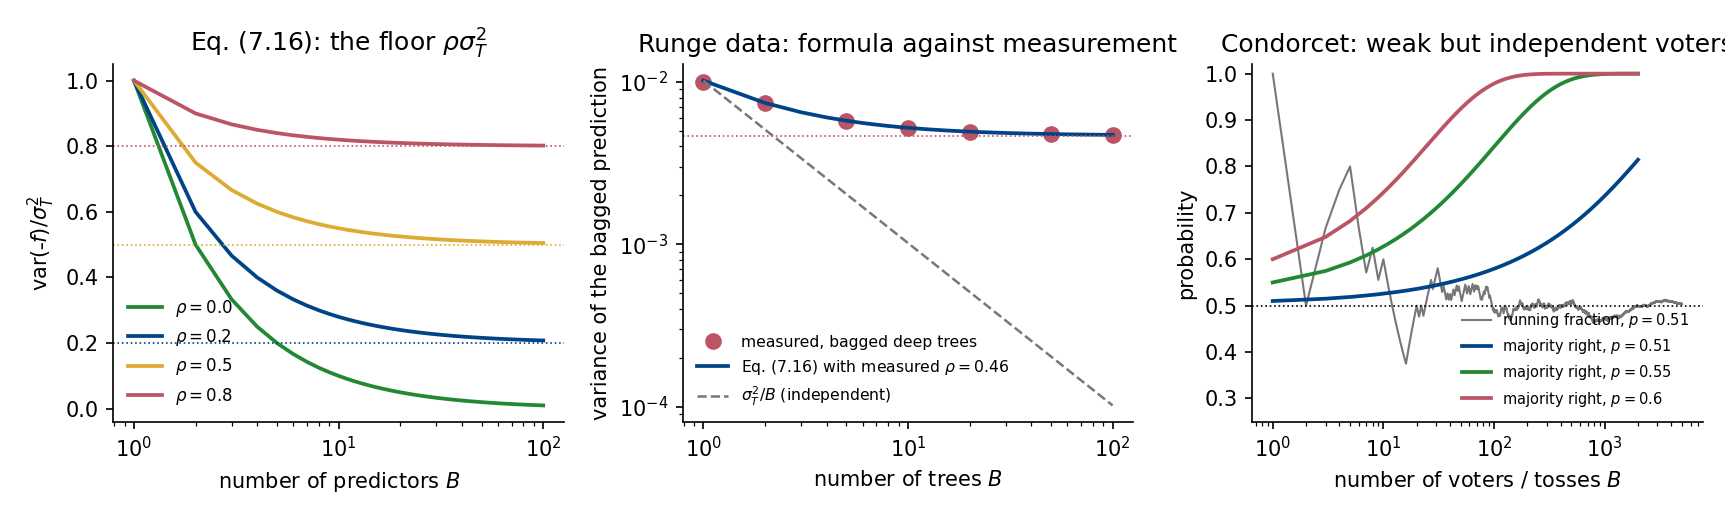

In [25]:
t0 = time.time()
sigma2, rho, Bs, measured = fig_variance("week46_variance.png")
print(f"({time.time() - t0:.0f} s)")
display(Image("week46_variance.png"))

Averaging a hundred trees removes about half the variance of one tree and
then stops: the floor $\rho\sigma_T^2$ with the measured $\rho\approx0.46$.
Lowering that floor is what the random forest is for.

### 4.2 Bagging and random forests from scratch (Section 7.10)

Bagging: bootstrap samples, deep unpruned trees, majority vote; the
out-of-bag score uses, for each point, only the trees that never saw it,
Eq. (7.17) (it must be called with the training rows in their original
order, and records in `oob_coverage_` the fraction of rows that received a
vote). `predict_proba` returns the fraction of trees voting for each class;
scikit-learn's bagging and forests instead average the trees' leaf class
proportions — the same for pure leaves, different otherwise (three trees
with class-1 probabilities $0.51, 0.51, 0.01$ vote 2:1 for class 1 but
average to $0.34$). The random forest is a subclass that passes
`max_features` ($m=\sqrt p$, Eq. 7.18) down to every tree, so that a fresh
random subset of features is drawn at every split.

In [26]:
class BaggingClassifier:
    """Bootstrap aggregation of unpruned trees, with out-of-bag scoring."""

    def __init__(self, n_estimators=100, max_depth=None, max_features=None,
                 rng=None):
        self.n_estimators, self.max_depth = n_estimators, max_depth
        self.max_features = max_features
        self.rng = np.random.default_rng(0) if rng is None else rng

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y)
        n = len(y)
        self.classes_ = np.unique(y)
        self.trees_, self.oob_ = [], []
        for _ in range(self.n_estimators):
            idx = self.rng.integers(0, n, n)             # bootstrap resample
            self.oob_.append(np.setdiff1d(np.arange(n), idx))
            tree = DecisionTree("classification", "gini", max_depth=self.max_depth,
                                max_features=self.max_features, rng=self.rng)
            self.trees_.append(tree.fit(X[idx], y[idx]))
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        votes = np.stack([t.predict(X) for t in self.trees_])
        out = np.empty(X.shape[0], dtype=self.classes_.dtype)
        for i in range(X.shape[0]):                      # majority vote
            counts = [np.sum(votes[:, i] == c) for c in self.classes_]
            out[i] = self.classes_[int(np.argmax(counts))]
        return out

    def predict_proba(self, X):
        """Fraction of trees voting for each class (hard votes; scikit-learn
        averages the leaf class proportions instead)."""
        X = np.asarray(X, dtype=float)
        votes = np.stack([t.predict(X) for t in self.trees_])
        return np.column_stack([np.mean(votes == c, axis=0) for c in self.classes_])

    def oob_score(self, X, y):
        """Eq. (7.17): each point is scored by the trees that never saw it.
        X, y must be the training rows in their original order."""
        X, y = np.asarray(X, dtype=float), np.asarray(y)
        tally = np.zeros((len(y), len(self.classes_)))
        for tree, oob in zip(self.trees_, self.oob_):
            if len(oob) == 0:
                continue
            pred = tree.predict(X[oob])
            for k, c in enumerate(self.classes_):
                tally[oob[pred == c], k] += 1
        seen = tally.sum(axis=1) > 0
        self.oob_coverage_ = seen.mean()                # fraction of rows with a vote
        vote = self.classes_[np.argmax(tally[seen], axis=1)]
        return np.mean(vote == y[seen])


class RandomForestClassifier(BaggingClassifier):
    """Bagging plus a random subset of m features at every split."""

    def __init__(self, n_estimators=100, max_depth=None, max_features="sqrt",
                 rng=None):
        super().__init__(n_estimators, max_depth, None, rng)
        self._mf = max_features

    def fit(self, X, y):
        p = np.asarray(X).shape[1]
        self.max_features = int(np.sqrt(p)) if self._mf == "sqrt" else self._mf
        return super().fit(X, y)                         # Eq. (7.18)


### 4.3 The moons: single tree, bagging, forest — ours and scikit-learn's

Test accuracy and out-of-bag accuracy for $B=100$ deep trees, and the
measured fraction of points left out of a bootstrap sample against $1/e$.
For an accuracy near 0.9 on 125 test points the standard error is about
0.027, so the differences between the four ensemble numbers are within the
noise (a proper comparison of two classifiers on the same test points is
paired — count the disagreements, McNemar's test); the out-of-bag numbers
(375 training points) are a useful second opinion.

In [27]:
def ensembles_moons(n=500, noise=0.3, B=100):
    """Section 7.10's table: single tree, bagging and random forest, ours and
    scikit-learn's, on the moons data, with out-of-bag accuracies."""
    from sklearn.datasets import make_moons
    from sklearn.model_selection import train_test_split
    from sklearn.tree import DecisionTreeClassifier
    from sklearn.ensemble import BaggingClassifier as SkBagging, RandomForestClassifier as SkForest
    X, y = make_moons(n_samples=n, noise=noise, random_state=SEED)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=SEED)
    rng = np.random.default_rng(SEED)
    out = {}
    t0 = time.time()
    single = DecisionTree("classification", "gini").fit(Xtr, ytr)
    out["single tree (ours)"] = (np.mean(single.predict(Xte) == yte), None)
    sk_single = DecisionTreeClassifier(random_state=SEED).fit(Xtr, ytr)
    out["single tree (sklearn)"] = (sk_single.score(Xte, yte), None)
    bag = BaggingClassifier(B, rng=rng).fit(Xtr, ytr)
    out["bagging (ours)"] = (np.mean(bag.predict(Xte) == yte), bag.oob_score(Xtr, ytr))
    oob_frac = np.mean([len(o) for o in bag.oob_]) / len(ytr)
    sk_bag = SkBagging(DecisionTreeClassifier(), n_estimators=B, oob_score=True, random_state=SEED).fit(Xtr, ytr)
    out["bagging (sklearn)"] = (sk_bag.score(Xte, yte), sk_bag.oob_score_)
    forest = RandomForestClassifier(B, rng=rng).fit(Xtr, ytr)
    out["forest (ours)"] = (np.mean(forest.predict(Xte) == yte), forest.oob_score(Xtr, ytr))
    sk_forest = SkForest(n_estimators=B, oob_score=True, random_state=SEED).fit(Xtr, ytr)
    out["forest (sklearn)"] = (sk_forest.score(Xte, yte), sk_forest.oob_score_)
    print(f"\nmoons n={n}, noise={noise}, B={B} ({time.time() - t0:.1f} s)")
    for k, (acc, oob) in out.items():
        print(f"  {k:24s} test acc = {acc:.4f}" + ("" if oob is None else f"   out-of-bag = {oob:.4f}"))
    print(f"  measured out-of-bag fraction {oob_frac:.4f} against 1/e = {np.exp(-1):.4f}")
    print(f"  test set: {len(yte)} points, standard error of an accuracy near 0.9: {np.sqrt(0.9 * 0.1 / len(yte)):.3f}")
    return out, oob_frac, (Xtr, Xte, ytr, yte, sk_single, sk_bag, sk_forest)


def fig_ensembles(fname="week46_ensembles.pdf"):
    from sklearn.tree import DecisionTreeClassifier
    from sklearn.ensemble import BaggingClassifier as SkBagging, RandomForestClassifier as SkForest
    out, oob_frac, (Xtr, Xte, ytr, yte, sk_single, sk_bag, sk_forest) = ensembles_moons()
    xx, yy = np.meshgrid(np.linspace(-1.8, 2.8, 300), np.linspace(-1.3, 1.8, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    fig, ax = plt.subplots(1, 4, figsize=(13.5, 3.4))
    models = [("single tree, full depth", sk_single), ("bagging, 100 trees", sk_bag),
              ("random forest, 100 trees", sk_forest)]
    for a, (title, m) in zip(ax, models):
        if hasattr(m, "predict_proba"):
            Z = m.predict_proba(grid)[:, 1].reshape(xx.shape)
        else:
            Z = m.predict(grid).reshape(xx.shape)
        a.contourf(xx, yy, Z, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.75)
        a.contour(xx, yy, Z, levels=[0.5], colors="k", linewidths=1)
        a.scatter(Xte[yte == 0, 0], Xte[yte == 0, 1], s=10, color=BLUE, edgecolor="k", lw=0.3)
        a.scatter(Xte[yte == 1, 0], Xte[yte == 1, 1], s=10, color=RED, edgecolor="k", lw=0.3)
        a.set_title(f"{title}\ntest acc {m.score(Xte, yte):.3f}", fontsize=9)
        a.set_xticks([])
        a.set_yticks([])

    Bs = [1, 2, 5, 10, 20, 50, 100, 200, 400]
    bag_te, bag_oob, rf_te, rf_oob = [], [], [], []
    import warnings
    warnings.filterwarnings("ignore")                        # few trees: some points have no oob vote
    for B in Bs:
        m = SkBagging(DecisionTreeClassifier(), n_estimators=B, oob_score=B >= 5, random_state=SEED).fit(Xtr, ytr)
        bag_te.append(m.score(Xte, yte))
        bag_oob.append(m.oob_score_ if B >= 5 else np.nan)
        m = SkForest(n_estimators=B, oob_score=B >= 5, random_state=SEED).fit(Xtr, ytr)
        rf_te.append(m.score(Xte, yte))
        rf_oob.append(m.oob_score_ if B >= 5 else np.nan)
    ax[3].plot(Bs, bag_te, "o-", color=BLUE, label="bagging, test")
    ax[3].plot(Bs, bag_oob, "o--", color=BLUE, alpha=0.6, label="bagging, out-of-bag")
    ax[3].plot(Bs, rf_te, "s-", color=RED, label="forest, test")
    ax[3].plot(Bs, rf_oob, "s--", color=RED, alpha=0.6, label="forest, out-of-bag")
    ax[3].set_xscale("log")
    ax[3].set_xlabel("number of trees $B$")
    ax[3].set_ylabel("accuracy")
    ax[3].set_title("More trees never hurt", fontsize=9)
    ax[3].set_ylim(0.79, 0.94)
    ax[3].legend(frameon=False, fontsize=6.5, loc="lower right")
    fig.tight_layout()
    fig.savefig(fname)
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)
    print("  accuracy against B (bagging test / oob, forest test / oob):")
    for row in zip(Bs, bag_te, bag_oob, rf_te, rf_oob):
        print("   B=%3d  %.3f %.3f  %.3f %.3f" % row)
    return out, oob_frac



moons n=500, noise=0.3, B=100 (11.7 s)
  single tree (ours)       test acc = 0.8240
  single tree (sklearn)    test acc = 0.8240
  bagging (ours)           test acc = 0.8960   out-of-bag = 0.9067
  bagging (sklearn)        test acc = 0.8720   out-of-bag = 0.9227
  forest (ours)            test acc = 0.8880   out-of-bag = 0.9093
  forest (sklearn)         test acc = 0.8800   out-of-bag = 0.9147
  measured out-of-bag fraction 0.3693 against 1/e = 0.3679
  test set: 125 points, standard error of an accuracy near 0.9: 0.027
  accuracy against B (bagging test / oob, forest test / oob):
   B=  1  0.840 nan  0.840 nan
   B=  2  0.856 nan  0.872 nan
   B=  5  0.872 0.867  0.880 0.859
   B= 10  0.864 0.904  0.896 0.907
   B= 20  0.864 0.904  0.864 0.917
   B= 50  0.856 0.925  0.880 0.915
   B=100  0.872 0.923  0.880 0.915
   B=200  0.888 0.917  0.880 0.912
   B=400  0.880 0.915  0.880 0.912


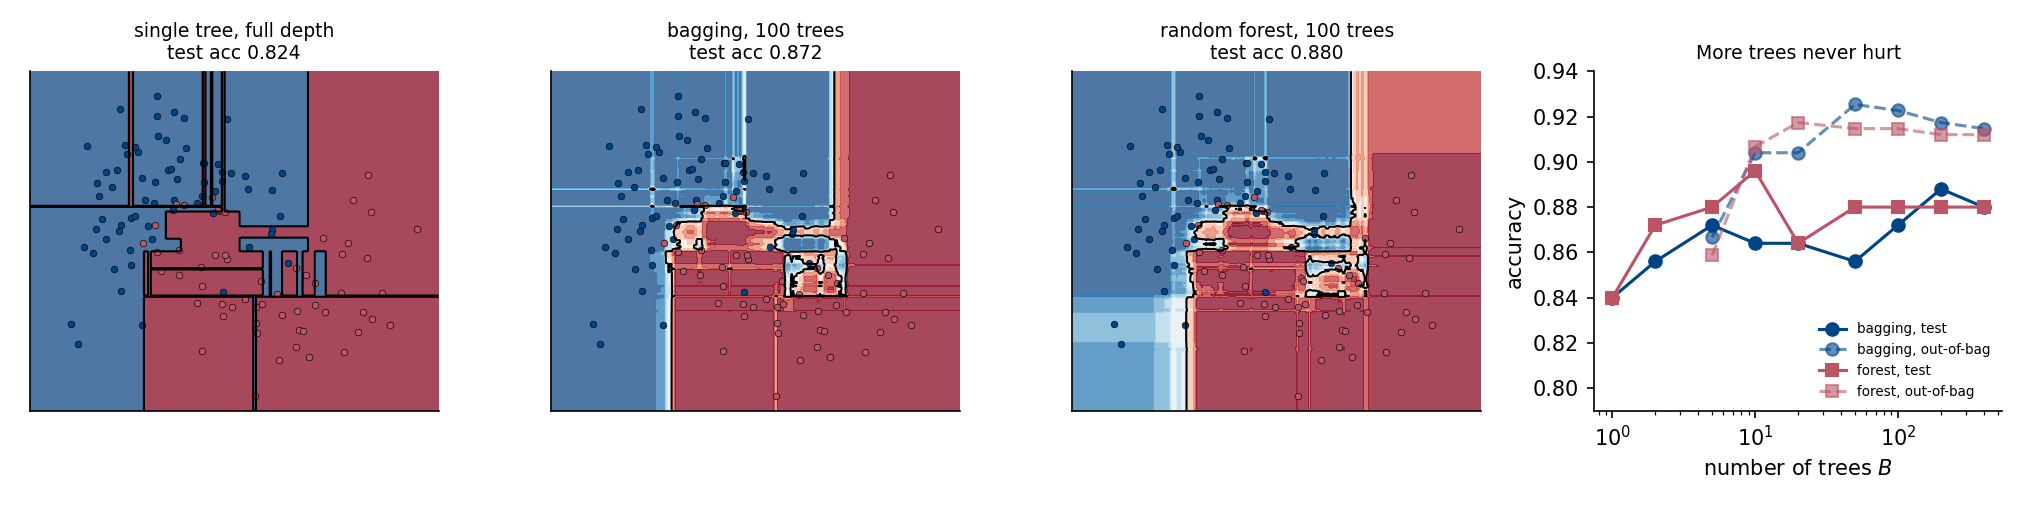

In [28]:
out, oob_frac = fig_ensembles("week46_ensembles.png")
display(Image("week46_ensembles.png"))

### 4.4 A real data set: the Wisconsin breast-cancer data

569 tumours, 30 features; a single tree at two depths, bagging and a random
forest with $B=200$, a scaled logistic regression for comparison, the mean
pairwise correlation between the trees' test-prediction vectors in the two
ensembles (a diagnostic of diversity across the test points, not the
fixed-$x$ $\rho$ of Eq. 7.16), the forest's feature importances, and a scan
over $m$ showing that correlation rise towards the bagging value as $m\to p$
while the out-of-bag accuracy moves by about two tumours either way.

In [29]:
def tree_correlation(ensemble, X):
    """Mean pairwise correlation between the 0/1 predictions of the trees of a
    fitted scikit-learn bagging ensemble or forest: the rho of Eq. (7.16)."""
    P = np.stack([t.predict(X) for t in ensemble.estimators_]).astype(float)
    C = np.corrcoef(P)
    return np.nanmean(C[np.triu_indices(len(P), 1)])


def cancer_study(fname="week46_cancer.pdf", B=200):
    """The Wisconsin breast-cancer data (569 samples, 30 features): a single
    tree at two depths, bagging and a random forest, test and out-of-bag
    accuracy, the measured correlation between trees, feature importances."""
    from sklearn.datasets import load_breast_cancer
    from sklearn.model_selection import train_test_split
    from sklearn.tree import DecisionTreeClassifier
    from sklearn.ensemble import BaggingClassifier as SkBagging, RandomForestClassifier as SkForest
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import make_pipeline
    data = load_breast_cancer()
    X, y = data.data, data.target
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)
    res = {}
    t3 = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(Xtr, ytr)
    res["tree, depth 3"] = (t3.score(Xtr, ytr), t3.score(Xte, yte), None)
    tf = DecisionTreeClassifier(random_state=SEED).fit(Xtr, ytr)
    res[f"tree, full depth ({tf.get_depth()})"] = (tf.score(Xtr, ytr), tf.score(Xte, yte), None)
    bag = SkBagging(DecisionTreeClassifier(), n_estimators=B, oob_score=True, random_state=SEED).fit(Xtr, ytr)
    res[f"bagging, {B} trees"] = (bag.score(Xtr, ytr), bag.score(Xte, yte), bag.oob_score_)
    rf = SkForest(n_estimators=B, max_features="sqrt", oob_score=True, random_state=SEED).fit(Xtr, ytr)
    res[f"random forest, {B} trees, m=sqrt(p)=5"] = (rf.score(Xtr, ytr), rf.score(Xte, yte), rf.oob_score_)
    lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(Xtr, ytr)
    res["logistic regression (scaled)"] = (lr.score(Xtr, ytr), lr.score(Xte, yte), None)
    rho_bag, rho_rf = tree_correlation(bag, Xte), tree_correlation(rf, Xte)
    print("\nWisconsin breast cancer, %d train / %d test, %d features" % (len(ytr), len(yte), X.shape[1]))
    for k, (tr, te, oob) in res.items():
        print(f"  {k:38s} train {tr:.4f}  test {te:.4f}" + ("" if oob is None else f"  oob {oob:.4f}"))
    print(f"  mean pairwise correlation of tree predictions: bagging {rho_bag:.3f}, forest {rho_rf:.3f}")
    # m scan
    ms = [1, 2, 3, 5, 8, 12, 20, 30]
    m_oob, m_rho = [], []
    for m in ms:
        f = SkForest(n_estimators=B, max_features=m, oob_score=True, random_state=SEED).fit(Xtr, ytr)
        m_oob.append(f.oob_score_)
        m_rho.append(tree_correlation(f, Xte))
    print("  m scan (m, oob accuracy, rho):", ", ".join(f"({m}, {o:.3f}, {r:.2f})" for m, o, r in zip(ms, m_oob, m_rho)))

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})
    imp = rf.feature_importances_
    order = np.argsort(imp)[::-1][:12]
    ax[0].barh(range(len(order))[::-1], imp[order], color=BLUE)
    ax[0].set_yticks(range(len(order))[::-1])
    ax[0].set_yticklabels([data.feature_names[i] for i in order], fontsize=8)
    ax[0].set_xlabel("mean decrease in Gini impurity (normalised)")
    ax[0].set_title("Random forest: the twelve most important features", fontsize=9.5)
    ax[1].plot(ms, m_oob, "o-", color=BLUE, label="out-of-bag accuracy")
    ax[1].set_xlabel("features tried at each split, $m$")
    ax[1].set_ylabel("out-of-bag accuracy", color=BLUE)
    ax[1].axvline(np.sqrt(30), color=GREY, ls=":", lw=1)
    ax[1].text(np.sqrt(30) + 0.3, min(m_oob) + 0.001, "$\\sqrt{p}$", color=GREY, fontsize=8)
    a2 = ax[1].twinx()
    a2.plot(ms, m_rho, "s--", color=RED, label="tree correlation $\\rho$")
    a2.set_ylabel("mean correlation between trees", color=RED)
    a2.spines["top"].set_visible(False)
    ax[1].set_title("$m=p$ is bagging; smaller $m$ decorrelates", fontsize=9.5)
    fig.tight_layout()
    fig.savefig(fname)
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)
    return res, rho_bag, rho_rf, list(zip(ms, m_oob, m_rho))



Wisconsin breast cancer, 398 train / 171 test, 30 features
  tree, depth 3                          train 0.9774  test 0.9181
  tree, full depth (7)                   train 1.0000  test 0.9298
  bagging, 200 trees                     train 1.0000  test 0.9415  oob 0.9548
  random forest, 200 trees, m=sqrt(p)=5  train 1.0000  test 0.9532  oob 0.9573
  logistic regression (scaled)           train 0.9925  test 0.9649
  mean pairwise correlation of tree predictions: bagging 0.806, forest 0.782
  m scan (m, oob accuracy, rho): (1, 0.950, 0.68), (2, 0.957, 0.73), (3, 0.952, 0.76), (5, 0.957, 0.78), (8, 0.962, 0.78), (12, 0.955, 0.80), (20, 0.952, 0.81), (30, 0.960, 0.81)


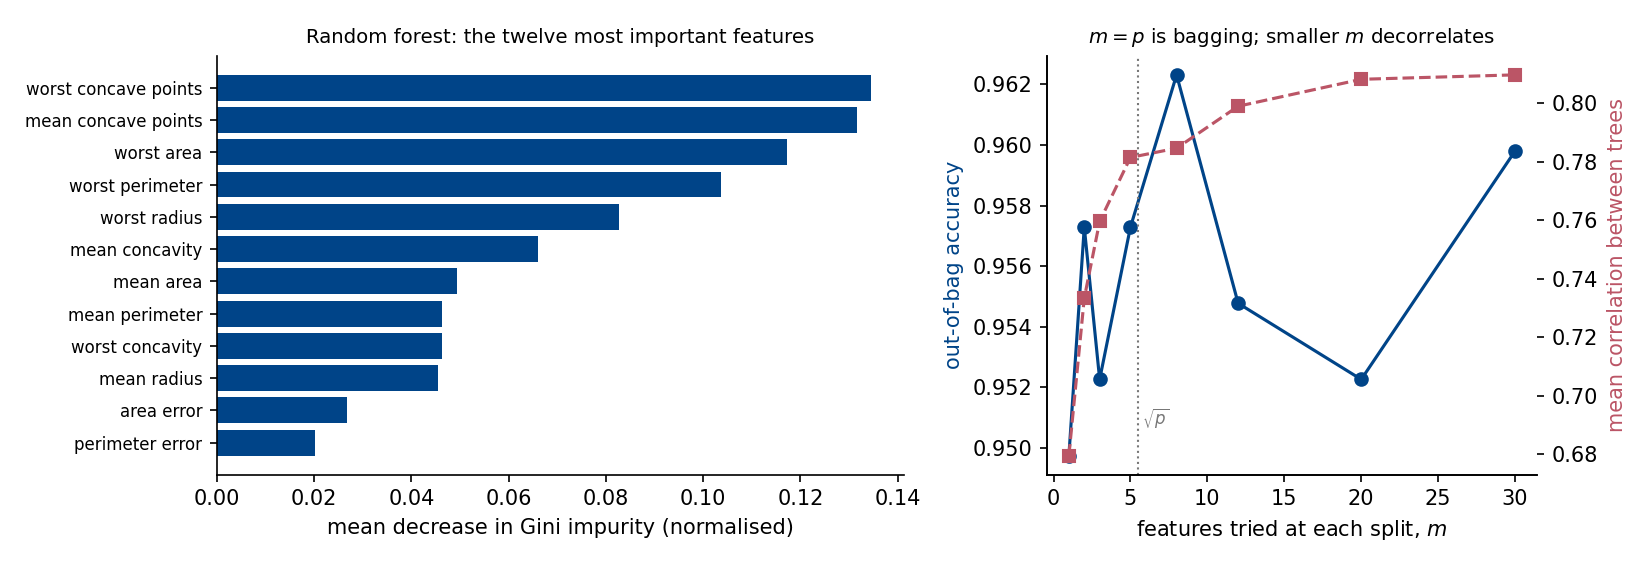

In [30]:
res, rho_bag, rho_rf, mscan = cancer_study("week46_cancer.png")
display(Image("week46_cancer.png"))

Three lessons: the ensembles beat the single tree; the forest decorrelates
only a little here because the 30 features are themselves strongly
correlated; and trees are not always best — on this nearly linearly separable
problem a scaled logistic regression wins. Forests are the safe default on
tabular data, not the guaranteed winner.

### 4.5 Ensembles as regressors: the Runge data once more

With a single feature there is nothing to subsample, so the random forest
*is* bagging; both remove part of the variance of the full-depth tree, and
what remains is the floor $\rho\sigma_T^2$ plus the bias of a
piecewise-constant fit (an average of staircases is a finer staircase, and no
tree extrapolates), so a degree-10 polynomial — the right inductive bias for
one smooth function — still wins.

In [31]:
def regression_ensembles():
    """Single tree, bagging and random forest as regressors on the Runge data,
    against a degree-10 polynomial (OLS) for reference."""
    from sklearn.tree import DecisionTreeRegressor
    from sklearn.ensemble import BaggingRegressor, RandomForestRegressor
    from sklearn.preprocessing import PolynomialFeatures
    from sklearn.linear_model import LinearRegression
    from sklearn.pipeline import make_pipeline
    X, y = runge_data(200)
    Xte, yte = runge_data(200, seed=SEED + 1)
    models = {
        "tree, depth 4": DecisionTreeRegressor(max_depth=4, random_state=SEED),
        "tree, full depth": DecisionTreeRegressor(random_state=SEED),
        "bagging, 200 deep trees": BaggingRegressor(DecisionTreeRegressor(), n_estimators=200, random_state=SEED),
        "random forest, 200 trees": RandomForestRegressor(n_estimators=200, random_state=SEED),
        "OLS, polynomial degree 10": make_pipeline(PolynomialFeatures(10), LinearRegression()),
    }
    print("\nRunge regression, test MSE (noise variance 0.01):")
    out = {}
    for k, m in models.items():
        m.fit(X, y)
        out[k] = np.mean((m.predict(Xte) - yte)**2)
        print(f"  {k:28s} {out[k]:.4f}")
    return out


In [32]:
out_reg = regression_ensembles()


Runge regression, test MSE (noise variance 0.01):
  tree, depth 4                0.0181
  tree, full depth             0.0214
  bagging, 200 deep trees      0.0173
  random forest, 200 trees     0.0173
  OLS, polynomial degree 10    0.0133


## Summary

* A tree partitions the feature space into axis-aligned boxes and predicts a
  constant in each. CART grows it top-down and greedily, scoring every
  feature and every midpoint by the weighted child impurity $C(k,t)$,
  Eq. (7.9) — MSE for regression, Gini index or entropy for classification —
  and keeping the largest gain, Eq. (7.10). Concave impurities reward pure
  children, which is why the Gini index and the entropy are preferred to the
  misclassification rate (Gini gain = variance between the children, entropy
  gain = mutual information; a zero gain may still be worth taking: XOR).
* Sixty lines of Python reproduce scikit-learn's trees; a fully grown tree has
  zero training error and large variance.
* $\mathrm{var}(\bar f)=\rho\sigma_T^2+(1-\rho)\sigma_T^2/B$, Eq. (7.16), at a
  fixed input and across training sets, is the design specification for
  every ensemble. Bagging shrinks the second term
  (bootstrap samples, deep trees, vote or average, out-of-bag error for free);
  the random forest lowers $\rho$ by offering only $m\approx\sqrt p$ random
  features at each split.
* Next week: boosting, the route that reduces the bias averaging leaves alone.